In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
# Remove pandas display limits
# pd.set_option("display.max_rows", 50)
# pd.set_option("display.max_columns", None)
# pd.set_option("display.max_colwidth", None)
# pd.set_option("display.width", None)

In [3]:
CAPACITY = 140
NOMINAL_TAPPING_WEIGHT = 122.5
T_POWER = 120

In [4]:
df_combined = pd.read_csv('data/prepared/df_combined.csv', index_col=0)

In [5]:
df_combined.info()

<class 'pandas.DataFrame'>
Index: 20427 entries, 0 to 20781
Data columns (total 71 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   HEATID                          20427 non-null  str    
 1   16A                             20427 non-null  float64
 2   25A                             20427 non-null  float64
 3   25A1                            20427 non-null  float64
 4   26A                             20427 non-null  float64
 5   3A                              20427 non-null  float64
 6   3ACh                            20427 non-null  float64
 7   3B23                            20427 non-null  float64
 8   AShM 75                         20427 non-null  float64
 9   Aluminum briquet                20427 non-null  float64
 10  Anthracite                      20427 non-null  float64
 11  Artificial graphite 0.1-2.5 mm  20427 non-null  float64
 12  B11                             20427 non-null  

In [6]:
df_combined.head()

,HEATID,16A,25A,25A1,26A,3A,3ACh,3B23,AShM 75,Aluminum briquet,...,OBM,Scrap_ratio,TEMP,O2_AMOUNT,GAS_AMOUNT,power_on,power_off,MW,stat_MW,Calc_tap_mass
0,5F0002,0.0,0.0,0.0,0.0,105928.0,0.0,0.0,0.0,0.0,...,17560.0,0.857800,1598.0,3659.0,1160.0,16.83,24.17,48.625,333.994756,109.102950
1,5F0003,0.0,0.0,0.0,0.0,108033.0,0.0,0.0,0.0,0.0,...,15320.0,0.875804,1653.0,3469.0,1117.0,33.50,5.50,48.625,359.657777,108.864887
2,5F0004,0.0,0.0,0.0,0.0,128245.0,0.0,0.0,0.0,0.0,...,0.0,1.000000,1636.0,3605.0,1204.0,34.33,19.67,47.375,351.895788,113.268938
3,5F0005,0.0,0.0,0.0,0.0,106941.0,0.0,0.0,0.0,0.0,...,16820.0,0.864093,1628.0,3678.0,1191.0,35.68,6.32,49.250,344.080465,109.233963
4,5F0006,0.0,0.0,0.0,0.0,127035.0,0.0,0.0,0.0,0.0,...,0.0,1.000000,1620.0,3655.0,1171.0,35.00,7.00,49.875,335.420295,112.179313


In [7]:
df_combined.columns

Index(['HEATID', '16A', '25A', '25A1', '26A', '3A', '3ACh', '3B23', 'AShM 75',
       'Aluminum briquet', 'Anthracite', 'Artificial graphite 0.1-2.5 mm',
       'B11', 'B68', 'Briquet BMK-60', 'Briquets 6A', 'CCM 03-10mm',
       'CCM 30-60 mm', 'Coke 10-30 mm', 'Dolomite', 'FGM material',
       'FMN 78 GOST4755-91 class 4', 'FOMI', 'FOMI B2', 'FeCr 850A', 'FeCr025',
       'FeSi 45', 'FeSi65-4', 'Ferrous scrap 6A', 'Flux FIM', 'Flux FM-2-1',
       'High-carbon ferrochromium', 'Hot briquet iron',
       'In-house produced lime', 'Iron scrap', 'KRS-65', 'KRS-65 briquets',
       'KShU 75', 'Ladle scrap', 'Lime', 'Lime, grade 2', 'Liquid scrap',
       'Magma', 'Magma-P', 'Magnesite brick scrap', 'MnSi17A',
       'Mo material briquet', 'Mo pellets', 'SIMP-RM', 'Scrap 3B22',
       'Scrap B23', 'Scrap G/B 25A', 'Scrap G/B 25AS',
       'Secondary aluminum AV 87', 'Separation scrap', 'Separation waste 3A',
       'Shram 75', 'Steel scrap G/B 25A', 'Steelmaking iron', 'Vanadium alloy',
 

## Scrap addition

In [8]:
scrap_columns = [
    "3A",
    "Liquid scrap",
    "16A",
    "25A",
    "25A1",
    "26A",
    # "3A (shop pipe waste)",
    "3ACh",
    "3B23",
    "Ferrous scrap 6A",
    "Iron scrap",
    "Ladle scrap",
    "Scrap 3B22",
    "Scrap B23",
    "Scrap G/B 25A",
    "Scrap G/B 25AS",
    "Separation scrap",
    "Separation waste 3A",
    "Steel scrap G/B 25A",
    "B11",
    "B68",
    "Briquet BMK-60",
    "Briquets 6A",
]

In [9]:
round(df_combined[scrap_columns].describe(), 1)

,3A,Liquid scrap,16A,25A,25A1,26A,3ACh,3B23,Ferrous scrap 6A,Iron scrap,...,Scrap B23,Scrap G/B 25A,Scrap G/B 25AS,Separation scrap,Separation waste 3A,Steel scrap G/B 25A,B11,B68,Briquet BMK-60,Briquets 6A
count,20427.0,20427.0,20427.0,20427.0,20427.0,20427.0,20427.0,20427.0,20427.0,20427.0,...,20427.0,20427.0,20427.0,20427.0,20427.0,20427.0,20427.0,20427.0,20427.0,20427.0
mean,116633.2,192.1,5068.5,198.3,1986.3,9.5,2054.0,2.7,1046.8,76.8,...,31.9,573.5,123.8,37.7,60.6,252.8,478.1,2.7,0.3,50.7
std,15475.4,3020.5,4832.5,1054.2,4576.8,284.4,7909.8,148.3,2783.3,544.7,...,715.8,1971.2,796.6,539.2,780.4,1641.2,4543.1,91.6,13.3,437.1
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,109600.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50%,120315.0,0.0,5070.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
75%,127440.0,0.0,8870.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,214225.0,125000.0,49366.0,20854.0,36268.0,13890.0,75137.0,10052.0,48963.0,8195.0,...,31843.7,21118.0,10280.0,27316.0,20490.0,39590.0,88360.0,3760.0,558.0,13500.0


<Axes: xlabel='Scrap_ratio', ylabel='Count'>

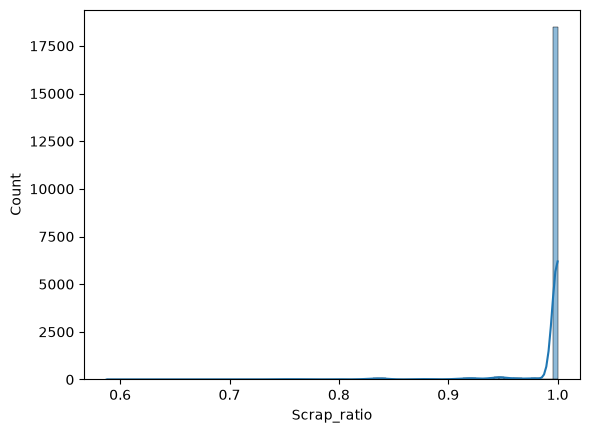

In [10]:
sns.histplot(df_combined['Scrap_ratio'], bins=100, kde=True)

## Tap mass

<Axes: xlabel='Calc_tap_mass', ylabel='Count'>

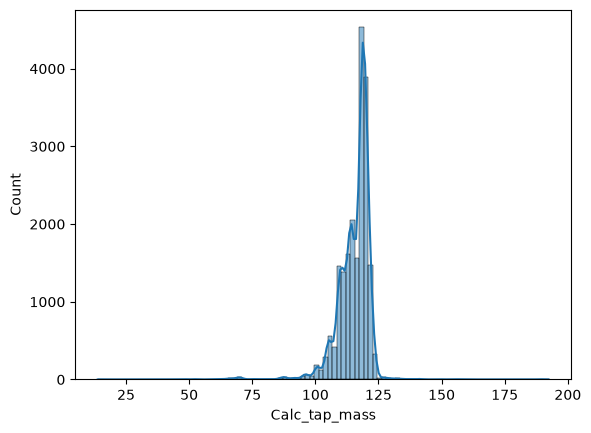

In [11]:
sns.histplot(df_combined['Calc_tap_mass'], bins=100, kde=True)

In [12]:
df_combined['Calc_tap_mass'].apply([np.min, np.max, np.mean, np.median, np.std]).round(1)

min        13.8
max       192.4
mean      115.3
median    117.5
std         7.2
Name: Calc_tap_mass, dtype: float64

## Energy

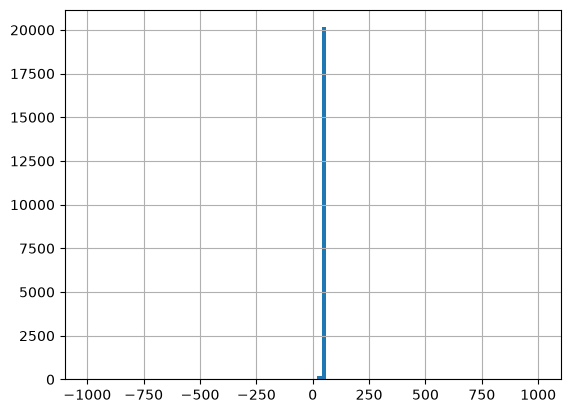

In [136]:
df_combined['MW'].hist(bins=100);

In [137]:
df_combined['MW'].describe()

count    20427.000000
mean        48.475015
std         10.503432
min       -999.999000
25%         47.000000
50%         48.750000
75%         50.250000
max        999.999000
Name: MW, dtype: float64

In [143]:
df_combined.loc[
    (df_combined["MW"] < df_combined["MW"].median() - 3 * df_combined["MW"].std())
    | (df_combined["MW"] > df_combined["MW"].median() + 3 * df_combined["MW"].std()),
    "MW",
]

4880      15.250
5278       0.000
6435      11.125
6443      15.500
9467    -999.999
9468     999.999
10289     12.000
14280      0.875
14396     16.375
14492      1.625
14510     10.875
14630     12.750
14649      3.000
14868     14.000
14899     14.625
15000      9.500
15004     13.750
15015     17.125
15028      7.000
16472     85.000
17661     11.750
18112     15.500
18929      2.500
20626      4.000
Name: MW, dtype: float64

In [144]:
df_combined = df_combined.loc[
        (df_combined['MW'] > df_combined['MW'].median() - 3 * df_combined['MW'].std())
        & (df_combined['MW'] < df_combined['MW'].median() + 3 * df_combined['MW'].std())]

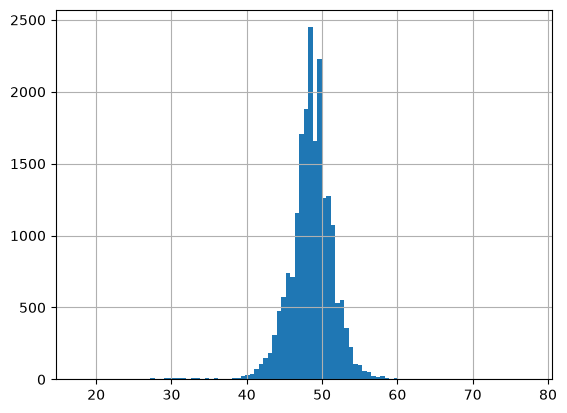

In [145]:
df_combined['MW'].hist(bins=100);

## OBM

<Axes: >

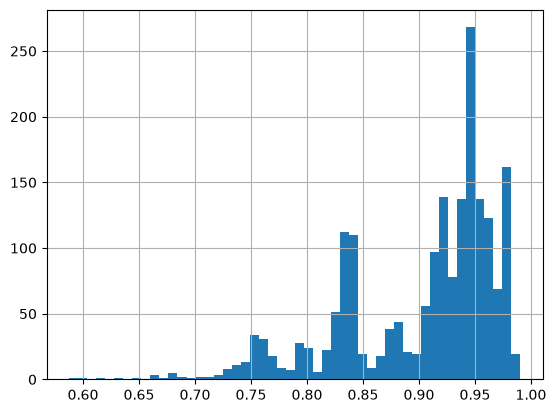

In [146]:
df_combined.loc[df_combined['Scrap_ratio'] < 1, 'Scrap_ratio'].hist(bins=50)

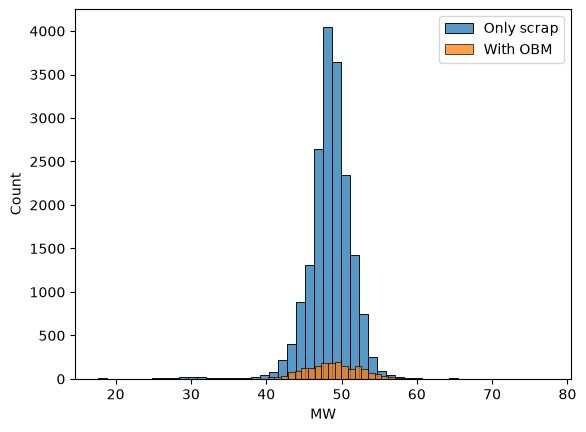

Average energy consumption with OBM: 48.8 MW
Average energy consumption without OBM: 48.5 MW


In [147]:
sns.histplot(df_combined.loc[df_combined['Scrap_ratio'] == 1, 'MW'], bins=50, label='Only scrap')
sns.histplot(df_combined.loc[df_combined['Scrap_ratio'] < 1, 'MW'], bins=50, label='With OBM')
plt.legend()
plt.show();

print(f"Average energy consumption with OBM: {df_combined.loc[df_combined['Scrap_ratio'] < 1, 'MW'].mean():.1f} MW")
print(f"Average energy consumption without OBM: {df_combined.loc[df_combined['Scrap_ratio'] == 1, 'MW'].mean():.1f} MW")

In [148]:
threshold = 0.9

print(f"Average energy consumption with high OBM: {df_combined.loc[df_combined['Scrap_ratio'] < threshold, 'MW'].mean():.1f} MW.")
print(f"Number of such heats {df_combined.loc[df_combined['Scrap_ratio'] < threshold, 'MW'].shape[0]} out of {df_combined.shape[0]}")
print(f"Average energy consumption without OBM: {df_combined.loc[df_combined['Scrap_ratio'] == 1, 'MW'].mean():.1f} MW")

Average energy consumption with high OBM: 46.8 MW.
Number of such heats 671 out of 20403
Average energy consumption without OBM: 48.5 MW


## NG and O2

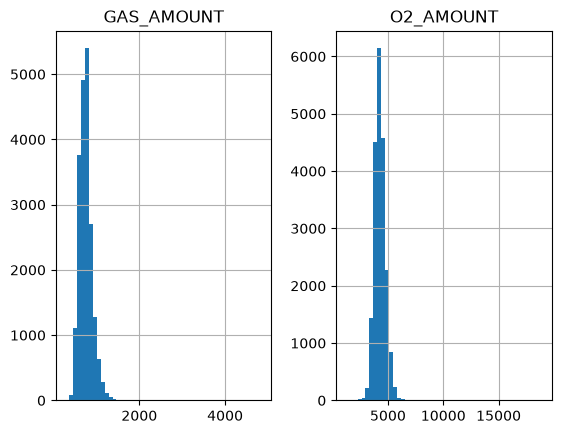

In [155]:
df_combined[['GAS_AMOUNT', 'O2_AMOUNT']].hist(bins=50);

In [156]:
columns_to_check = ['GAS_AMOUNT', 'O2_AMOUNT']

for col in columns_to_check:
    df_combined = df_combined.loc[
        (df_combined[col] > df_combined[col].median() - 3 * df_combined[col].std())
        & (df_combined[col] < df_combined[col].median() + 3 * df_combined[col].std())
    ]

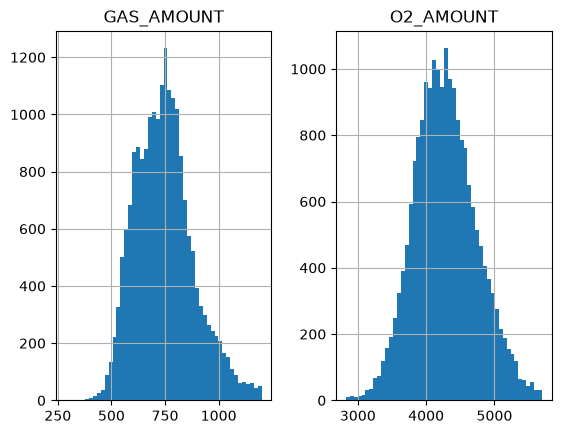

In [157]:
df_combined[['GAS_AMOUNT', 'O2_AMOUNT']].hist(bins=50);

## Time of the heat

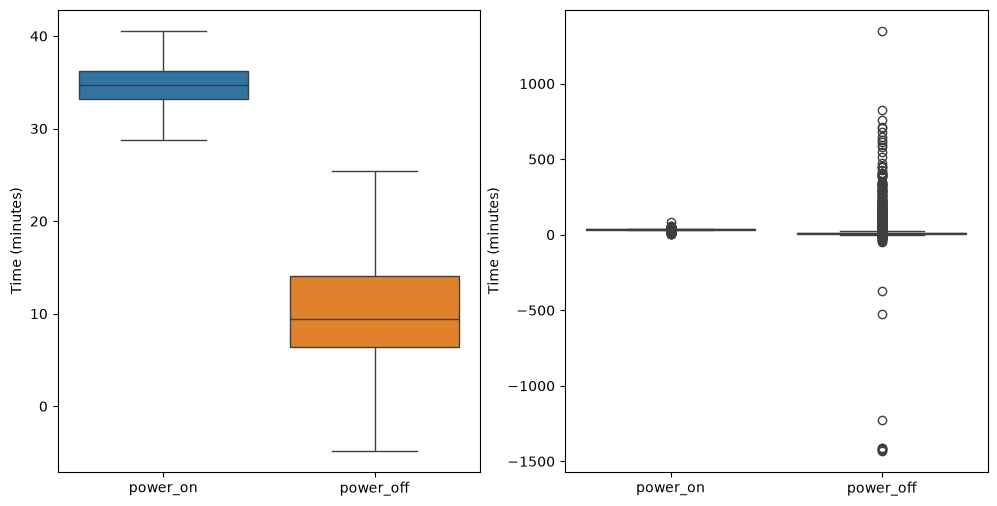

In [160]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
sns.boxplot(data=df_combined[['power_on', 'power_off']], orient='v', showfliers=False, ax=ax1);
sns.boxplot(data=df_combined[['power_on', 'power_off']], orient='v', showfliers=True, ax=ax2);

ax1.set_ylabel('Time (minutes)')
ax2.set_ylabel('Time (minutes)')

plt.show()

In [161]:
df_combined[['power_off', 'power_on']].describe()

,power_off,power_on
count,20063.000000,20063.000000
mean,13.904901,34.602102
std,37.917815,2.808223
min,-1431.300000,2.180000
25%,6.450000,33.220000
50%,9.380000,34.680000
75%,14.050000,36.170000
max,1348.670000,86.170000


In [162]:
columns_to_check = ['power_on', 'power_off']

for col in columns_to_check:
    df_combined = df_combined.loc[
        (df_combined[col] > df_combined[col].median() - 3 * df_combined[col].std())
        & (df_combined[col] < df_combined[col].median() + 3 * df_combined[col].std())
    ]

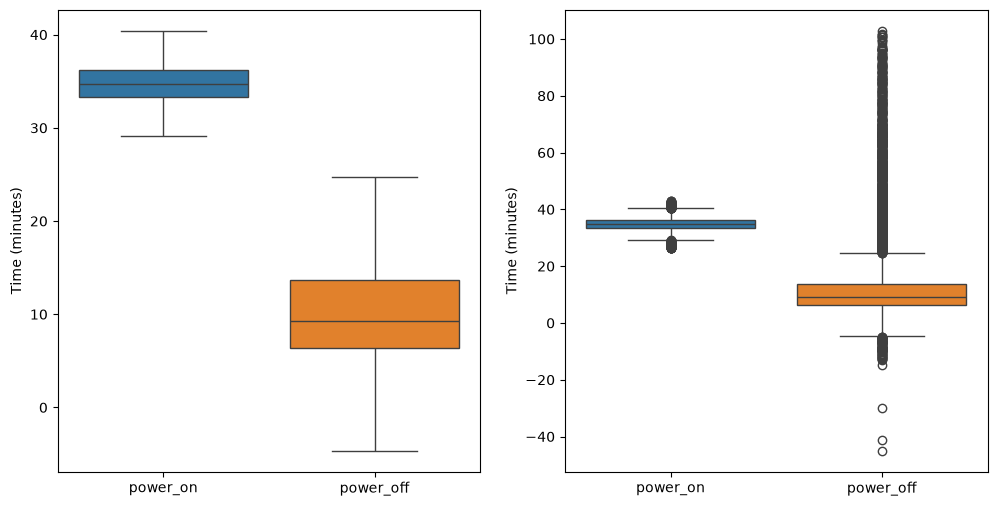

In [163]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
sns.boxplot(data=df_combined[['power_on', 'power_off']], orient='v', showfliers=False, ax=ax1);
sns.boxplot(data=df_combined[['power_on', 'power_off']], orient='v', showfliers=True, ax=ax2);

ax1.set_ylabel('Time (minutes)')
ax2.set_ylabel('Time (minutes)')

plt.show()

## Energy consumption and statistic formula

In [164]:
E_per_ton = df_combined['MW'] * 1000 / df_combined['Calc_tap_mass']
E_per_ton_nom = df_combined['MW'] * 1000 / NOMINAL_TAPPING_WEIGHT

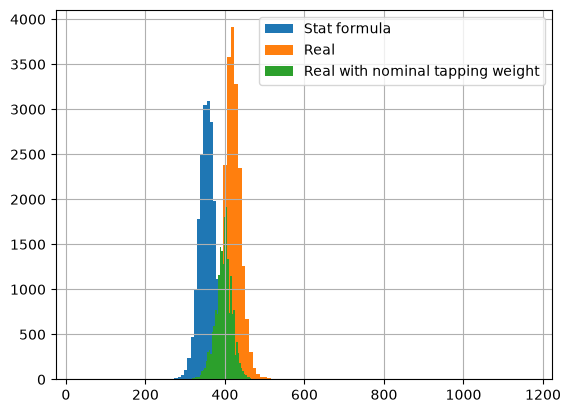

Mean energy consumption with stat formula: 355.5 kWh/t
Mean energy consumption in real: 421.4 kWh/t
Mean energy consumption with nominal tapping weight: 396.9 kWh/t


In [165]:
df_combined['stat_MW'].hist(bins=100, label="Stat formula");
E_per_ton.hist(bins=100, label="Real");
E_per_ton_nom.hist(bins=100, label="Real with nominal tapping weight");
plt.legend()
plt.show()

print(f"Mean energy consumption with stat formula: {df_combined['stat_MW'].mean():.1f} kWh/t")
print(f"Mean energy consumption in real: {E_per_ton.mean():.1f} kWh/t")
print(f"Mean energy consumption with nominal tapping weight: {E_per_ton_nom.mean():.1f} kWh/t")